# 03 — Modelagem Preditiva

## Objetivo

Desenvolver modelos de classificação para prever a aprovação de solicitações de cartão de crédito.

Nesta etapa serão utilizados dois algoritmos:
- Regressão Logística
- Árvore de Decisão

Os modelos serão avaliados com dados separados para teste, utilizando métricas de classificação.

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report
)

In [26]:
df_modelo = pd.read_csv("../data/processed/dados_modelagem.csv")

X = df_modelo.drop(columns=["aprovado"])
y = df_modelo["aprovado"]

print("Base carregada:", df_modelo.shape)
print("Variáveis preditoras:", X.shape[1])
print("Variável-alvo:", y.name)

Base carregada: (672, 7)
Variáveis preditoras: 6
Variável-alvo: aprovado


In [27]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Treinamento:", X_train.shape)
print("Teste:", X_test.shape)

Treinamento: (537, 6)
Teste: (135, 6)


In [28]:
modelo_logistico = Pipeline([
    ("padronizacao", StandardScaler()),
    ("modelo", LogisticRegression(max_iter=1000))
])

modelo_logistico.fit(X_train, y_train)

print("Regressão Logística treinada com sucesso!")

Regressão Logística treinada com sucesso!


In [29]:
y_pred_logistico = modelo_logistico.predict(X_test)

y_prob_logistico = modelo_logistico.predict_proba(X_test)[:, 1]

print("Previsões realizadas:", len(y_pred_logistico))

Previsões realizadas: 135


In [30]:
metricas_logistico = {
    "Acurácia": accuracy_score(y_test, y_pred_logistico),
    "Precisão": precision_score(y_test, y_pred_logistico),
    "Recall": recall_score(y_test, y_pred_logistico),
    "F1-Score": f1_score(y_test, y_pred_logistico),
    "ROC-AUC": roc_auc_score(y_test, y_prob_logistico)
}

for nome, valor in metricas_logistico.items():
    print(f"{nome}: {valor:.4f}")

Acurácia: 0.7852
Precisão: 0.8261
Recall: 0.6441
F1-Score: 0.7238
ROC-AUC: 0.8182


,Previsto: Reprovado,Previsto: Aprovado
Real: Reprovado,68,8
Real: Aprovado,21,38


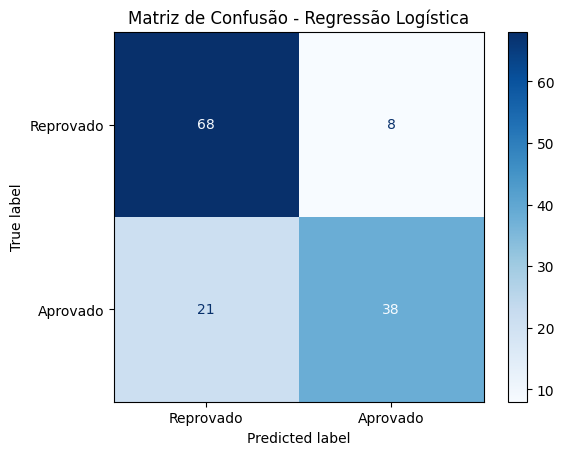

In [31]:
matriz = confusion_matrix(
    y_test,
    y_pred_logistico,
    labels=[0, 1]
)

display(
    pd.DataFrame(
        matriz,
        index=["Real: Reprovado", "Real: Aprovado"],
        columns=["Previsto: Reprovado", "Previsto: Aprovado"]
    )
)

ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=["Reprovado", "Aprovado"]
).plot(cmap="Blues")

plt.title("Matriz de Confusão - Regressão Logística")
plt.show()

In [32]:
modelo_arvore = DecisionTreeClassifier(
    max_depth=3,
    random_state=42
)

modelo_arvore.fit(X_train, y_train)

y_pred_arvore = modelo_arvore.predict(X_test)

y_prob_arvore = modelo_arvore.predict_proba(X_test)[:, 1]

print("Árvore de Decisão treinada com sucesso!")

Árvore de Decisão treinada com sucesso!


In [33]:
metricas_arvore = {
    "Acurácia": accuracy_score(y_test, y_pred_arvore),
    "Precisão": precision_score(y_test, y_pred_arvore),
    "Recall": recall_score(y_test, y_pred_arvore),
    "F1-Score": f1_score(y_test, y_pred_arvore),
    "ROC-AUC": roc_auc_score(y_test, y_prob_arvore)
}

for nome, valor in metricas_arvore.items():
    print(f"{nome}: {valor:.4f}")

Acurácia: 0.7481
Precisão: 0.7907
Recall: 0.5763
F1-Score: 0.6667
ROC-AUC: 0.8015


In [34]:
comparacao = pd.DataFrame(
    [metricas_logistico, metricas_arvore],
    index=["Regressão Logística", "Árvore de Decisão"]
)

display(comparacao.round(4))

,Acurácia,Precisão,Recall,F1-Score,ROC-AUC
Regressão Logística,0.7852,0.8261,0.6441,0.7238,0.8182
Árvore de Decisão,0.7481,0.7907,0.5763,0.6667,0.8015
